# MARTHA QC pools: teapot results

The steps of `ratio_MORPHEUS.ipynb` on teapot's results instead of a Skyline export: teapot's confident light/heavy pairs (`peptide.abs_quant.confident.tsv`, route `enc_dia`) of the 25 QC pool runs of the MARTHA study, plates 1 to 5, with their SDRF `sdrf/sdrf_MARTHA_pool.sdrf.tsv`.

In [1]:
# import sys, kardemumma
# print(sys.executable)         # kernel Python
# print(kardemumma.__file__)    # should point to your local repo under src/kardemumma

In [2]:
# Load packages
from pathlib import Path
import os
import re
import sys
import importlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Importantlly, import kardemumma :)
import kardemumma as kdm

In [3]:
# **SDRF**
sdrf_path = 'sdrf/sdrf_MARTHA_pool.sdrf.tsv'

kdm.readout_ms_type(sdrf_path)

Type(s) of MS experiment(s) in SDRF: NT=Parallel Reaction Monitoring;AC=MS:1002956


['NT=Parallel Reaction Monitoring;AC=MS:1002956']

In [4]:
# Read the sdrf file

sdrf_data = kdm.ImportSDRFFile(sdrf_path)
sdrf_data_file = sdrf_data.import_sdrf_file()

Importing SDRF file: sdrf/sdrf_MARTHA_pool.sdrf.tsv


In [5]:
# teapot results path
teapot_path = "data/MARTHA_teapot/enc_dia/peptide.abs_quant.confident.tsv"

# Import teapot results (includes column "Isotope Label Type"); File Name is the SDRF data file
teapot_importer = kdm.ImportTeapotFile(teapot_path)
teapot_data = teapot_importer.import_teapot_file(sdrf_df=sdrf_data_file)

Importing teapot file: data/MARTHA_teapot/enc_dia/peptide.abs_quant.confident.tsv
Route: enc_dia
Runs: 25  Proteins: 139  Peptidoforms: 280
Confident light/heavy pairs: 5611


teapot's runs are the SDRF's, so there are no QC injections to remove. teapot reports no library dot product: both forms of every confident pair were identified, so every pair counts, in both channels.

In [6]:
teapot_clean = kdm.pivot_confident_pairs(teapot_data)

Isotope Label Type
heavy    5611
light    5611
Name: count, dtype: int64


In [7]:
# Summarise each peptide to count how many heavy or light signals are present
peptide_counts = kdm.summarise_peptide_counts(teapot_clean)

In [8]:
report_summary, peptide_list = kdm.report_peptide_protein_summary(peptide_counts)

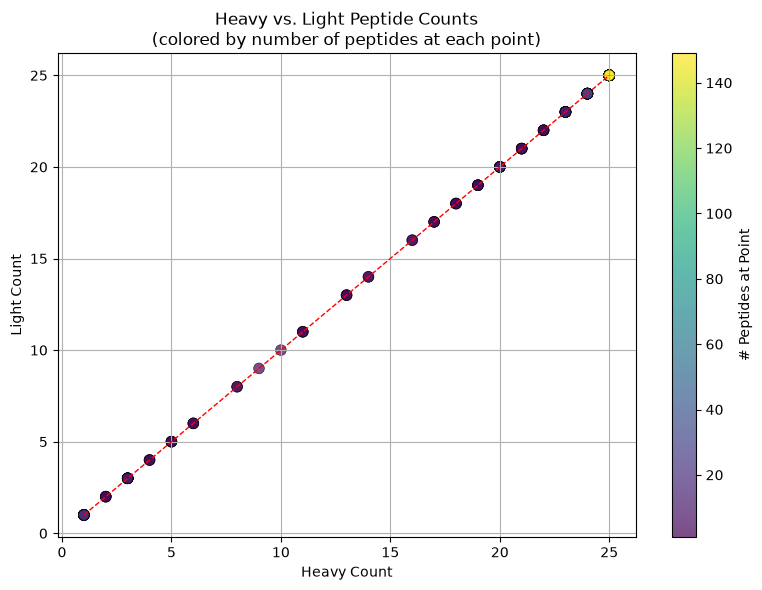

In [9]:
kdm.plot_heavy_light_scatter(peptide_counts)

In [10]:
# A confident pair in more than 12 of the 25 runs
filtered_peptide_counts = kdm.filter_peptide_counts(peptide_counts, light_cutoff=12, heavy_cutoff=12)

filtered_peptide_counts.head()

,Protein Name,Peptide,heavy_count,light_count
0,QR0140840_SERPINA6|P08185,ITQDAQLK,24,24
1,QR0140840_SERPINA6|P08185,MNTVIAALSR,25,25
2,QR0140840_SERPINA6|P08185,WSAGLTSSQVDLYIPK,25,25
3,QR0252445_ITIH3|Q06033,ALDLSLK,25,25
4,QR0252445_ITIH3|Q06033,DYIFGNYIER,25,25


In [11]:
selected_peptides_report, selected_peptides = kdm.report_peptide_protein_summary(filtered_peptide_counts)

In [12]:
teapot_merge_obj = kdm.MergeFiles(teapot_data, sdrf_data_file, selected_peptides)
teapot_merge = teapot_merge_obj.merge_files()

Sample names in Skyline but not in SDRF (0).
----------------------------------------
Sample names in SDRF but not in Skyline (0).


In [13]:
teapot_pool = teapot_merge_obj.select_pool_data( pool_label='Pool')

Summary of samples per plate:
Plate Plate_1: 5 unique comment[data file] names
Plate Plate_2: 5 unique comment[data file] names
Plate Plate_3: 5 unique comment[data file] names
Plate Plate_4: 5 unique comment[data file] names
Plate Plate_5: 5 unique comment[data file] names


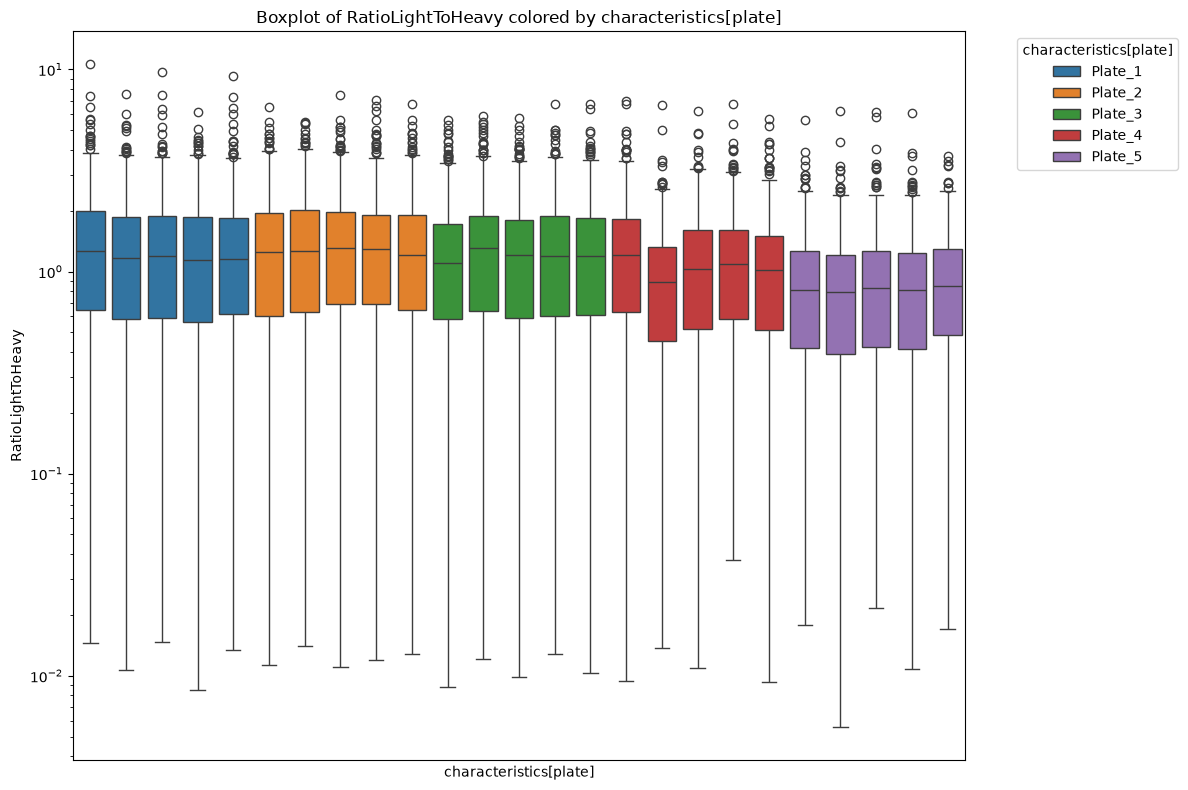

In [14]:
# Plot log_ratio of each sample in boxplot, colored by plate, but x-axis is Replicate, sorted by plate (though x labels are hidden).
kdm.plot_pool_boxplot(teapot_pool)

## Method 1: Per-plate multiplicative conversion factor (prm.py)

Compute intra-/inter-plate CV, select the lowest-CV peptides as a normalization reference set, then fit a single global correction factor per plate (`get_plate_conversion_factors`) and apply it (`adjust_ratio_by_plate`).

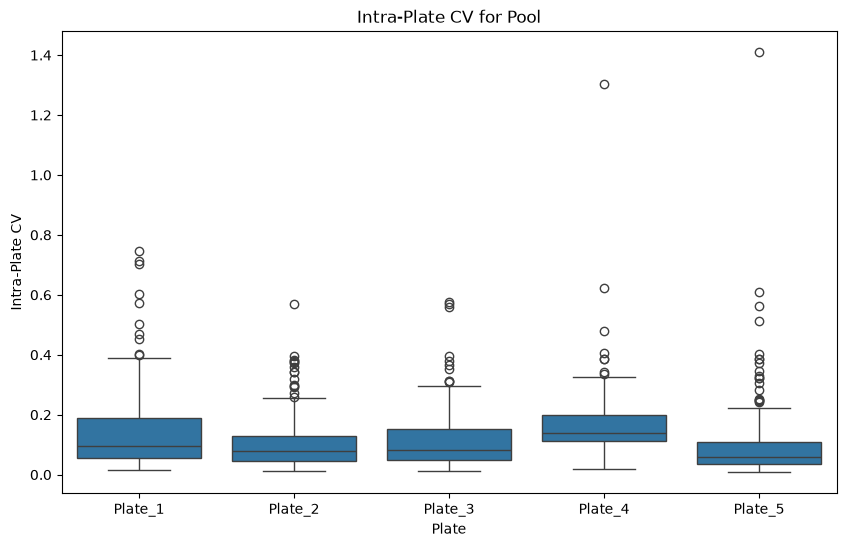

In [15]:
# Calculate intra-plate CV

peptide_plate_stats = kdm.calculate_intra_plate_cv(teapot_pool, col_name='characteristics[plate]')
kdm.plot_intra_plate_cv_stats(peptide_plate_stats, col_name='characteristics[plate]')

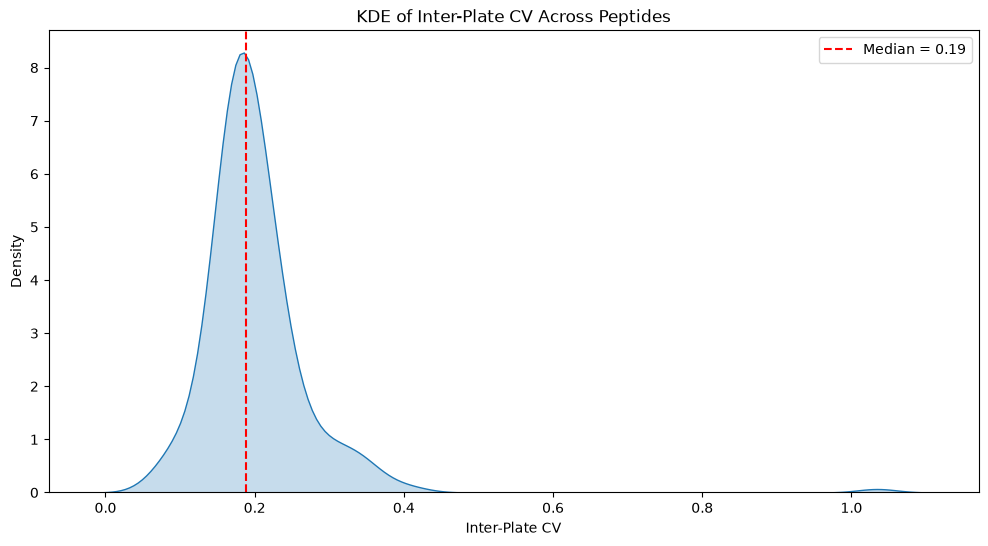

In [16]:
interplate_cv = kdm.calculate_inter_plate_cv(peptide_plate_stats)
kdm.plot_inter_plate_cv_kde(interplate_cv)

In [17]:
interplate_cv.head()

,Peptide Sequence,grand_mean,between_plate_sd,inter_plate_cv
0,TNLESILSYPK,1.894914,0.113277,0.059779
1,SQCTYSNPEGTVVLACDQAQCR,0.844044,0.064420,0.076323
2,QEELCLAR,0.620455,0.050799,0.081873
3,LLDSLPSDTR,1.726462,0.144862,0.083907
4,LSCSYSHWSAPAPQCK,0.836013,0.073937,0.088440


In [18]:
# Print interplate_cv froom low to high
print('This is the interplate_cv from low to high:')
print(interplate_cv[interplate_cv['inter_plate_cv'] < 0.1])

This is the interplate_cv from low to high:
         Peptide Sequence  grand_mean  between_plate_sd  inter_plate_cv
0             TNLESILSYPK    1.894914          0.113277        0.059779
1  SQCTYSNPEGTVVLACDQAQCR    0.844044          0.064420        0.076323
2                QEELCLAR    0.620455          0.050799        0.081873
3              LLDSLPSDTR    1.726462          0.144862        0.083907
4        LSCSYSHWSAPAPQCK    0.836013          0.073937        0.088440
5    FCPDGSPSECHEHADCVLER    0.069137          0.006114        0.088440


Total peptides: 229
  CV < 10%: 6 peptides
  CV < 20%: 144 peptides


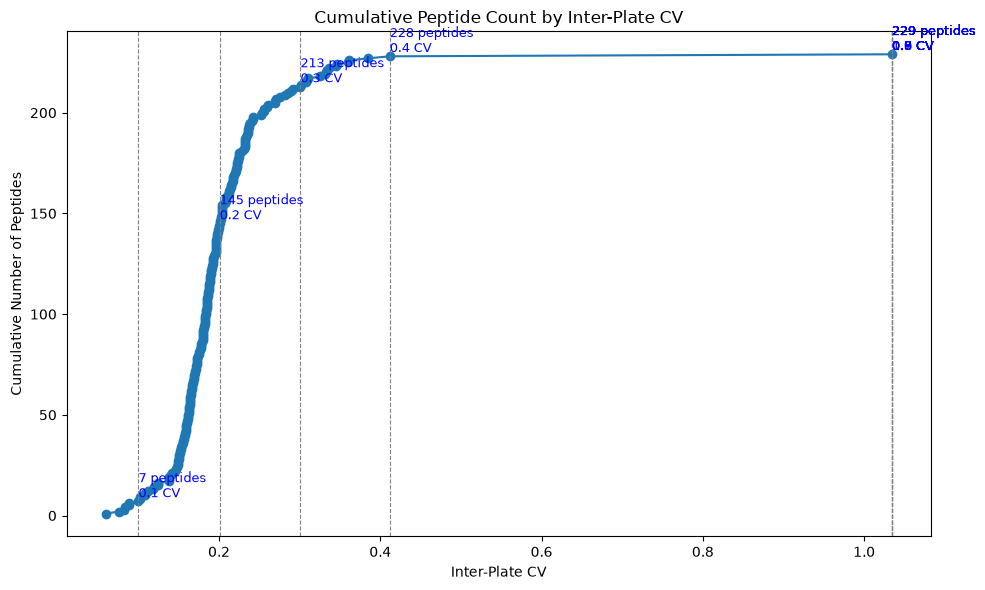

In [19]:
kdm.plot_cumulative_peptide_count_by_cv(interplate_cv)

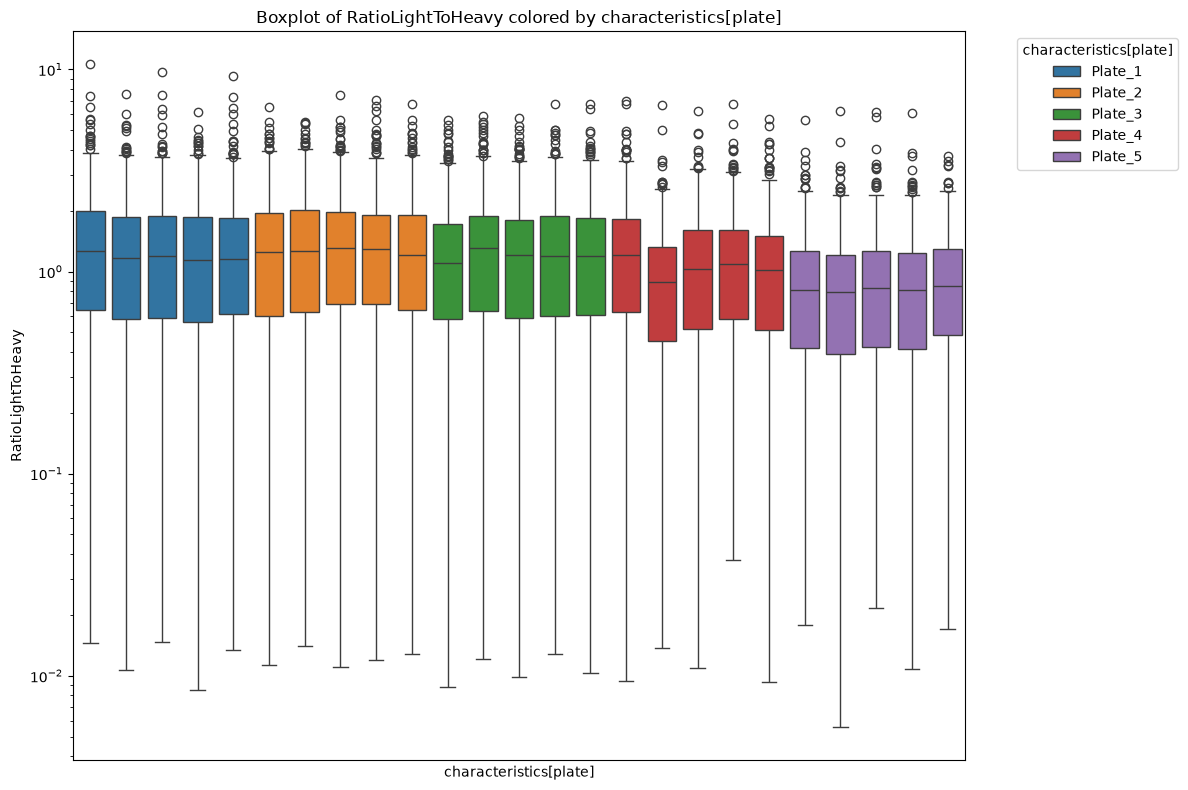

In [20]:
kdm.plot_pool_boxplot(teapot_pool)

In [21]:
# Normalization peptides: inter-plate CV at most 30 %
selected_peptides = kdm.get_lowest_cv_peptides(interplate_cv, 30)
len(selected_peptides)

212

In [22]:
# Batch/Plate adjustment, correcting for each peptide within each plate (batch) 
# using only the normalization peptides

pool_selected_df = teapot_pool[teapot_pool['Peptide Sequence'].isin(selected_peptides)]
pool_selected_df

,Precursor,Replicate,File Name,Peptide Retention Time,Precursor Charge,Peptide Sequence,Peptide,Normalized Area,RatioLightToHeavy,Protein Name,...,characteristics[ancestry category],characteristics[cell type],characteristics[cell line],characteristics[disease],characteristics[96w_pos],characteristics[96w_plate_coordinate],characteristics[LIMS_ID],characteristics[individual],characteristics[biological replicate],factor value[Sample]
0,AAVYHHFISDGVR++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,14.665567,2,AAVYHHFISDGVR,AAVYHHFISDGVR,2122600.0,NaN,QR0280090_C3|P01024,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
1,AAVYHHFISDGVR++,PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,14.663415,2,AAVYHHFISDGVR,AAVYHHFISDGVR,2540990.0,1.197112,QR0280090_C3|P01024,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
2,AAVYHHFISDGVRK+++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,13.181308,3,AAVYHHFISDGVRK,AAVYHHFISDGVRK,2805000.0,NaN,QR0280090_C3|P01024,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
3,AAVYHHFISDGVRK+++,PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,13.151115,3,AAVYHHFISDGVRK,AAVYHHFISDGVRK,3376620.0,1.203786,QR0280090_C3|P01024,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
4,AC[+57.0]IPTGPYPC[+57.0]GK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,16.440113,2,ACIPTGPYPCGK,AC[+57.0]IPTGPYPC[+57.0]GK,1147820.0,NaN,QR3730418_F10|P00742,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10861,YRITENDIQIALDDAK+++,PRM_20251207_MarthaReselection_Plate_5_H12,PRM_20251207_MarthaReselection_Plate_5_H12.raw,22.123517,3,YRITENDIQIALDDAK,YRITENDIQIALDDAK,30582.1,0.675565,QR5000600_APOB|P04114,...,not available,not available,not available,not available,96,Plate_5_H12,EMPTY-0001,not available,1,Pool
10862,YVMLPVADQDQC[+57.0]IR++ (heavy),PRM_20251207_MarthaReselection_Plate_5_H12,PRM_20251207_MarthaReselection_Plate_5_H12.raw,22.056742,2,YVMLPVADQDQCIR,YVMLPVADQDQC[+57.0]IR,15430100.0,NaN,QR5000013_HP|P00738,...,not available,not available,not available,not available,96,Plate_5_H12,EMPTY-0001,not available,1,Pool
10863,YVMLPVADQDQC[+57.0]IR++,PRM_20251207_MarthaReselection_Plate_5_H12,PRM_20251207_MarthaReselection_Plate_5_H12.raw,22.056502,2,YVMLPVADQDQCIR,YVMLPVADQDQC[+57.0]IR,17123700.0,1.109759,QR5000013_HP|P00738,...,not available,not available,not available,not available,96,Plate_5_H12,EMPTY-0001,not available,1,Pool
10864,YYC[+57.0]FQGNQFLR++ (heavy),PRM_20251207_MarthaReselection_Plate_5_H12,PRM_20251207_MarthaReselection_Plate_5_H12.raw,22.171005,2,YYCFQGNQFLR,YYC[+57.0]FQGNQFLR,2875630.0,NaN,QR4200150_HPX|P02790,...,not available,not available,not available,not available,96,Plate_5_H12,EMPTY-0001,not available,1,Pool


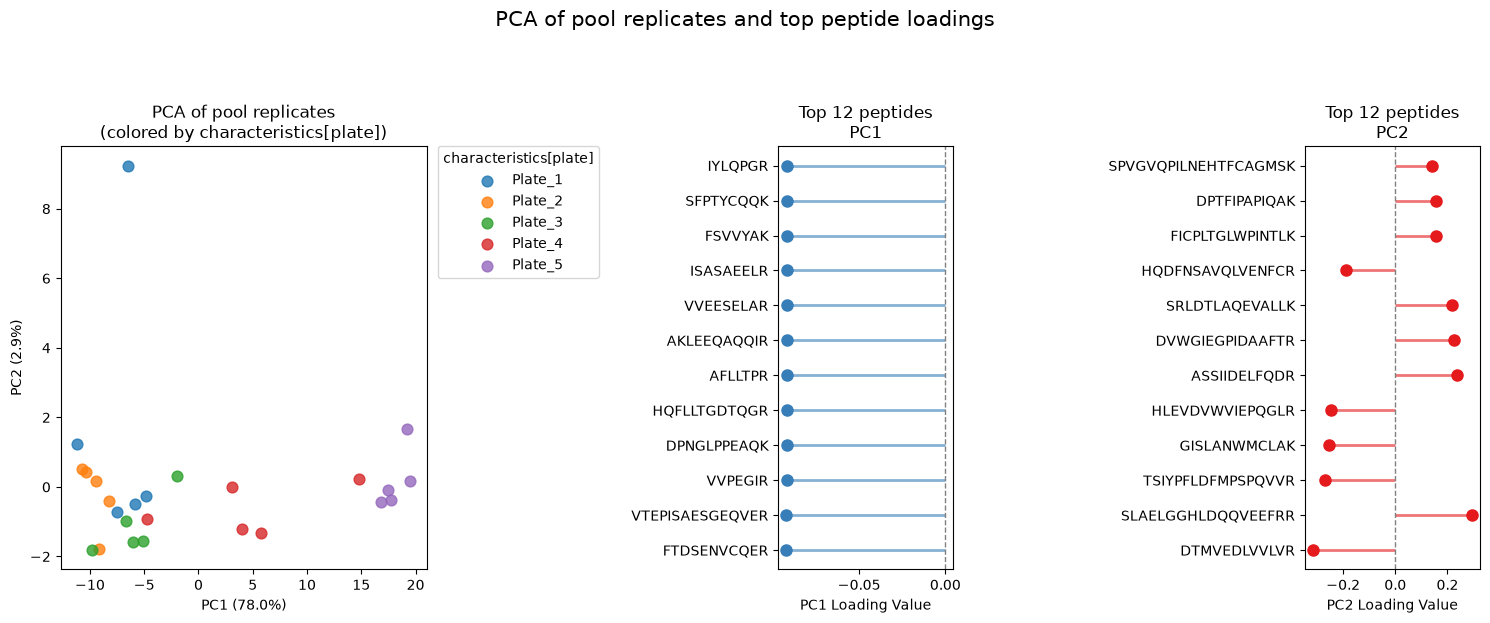

In [23]:
kdm.plot_pool_pca(teapot_merge)

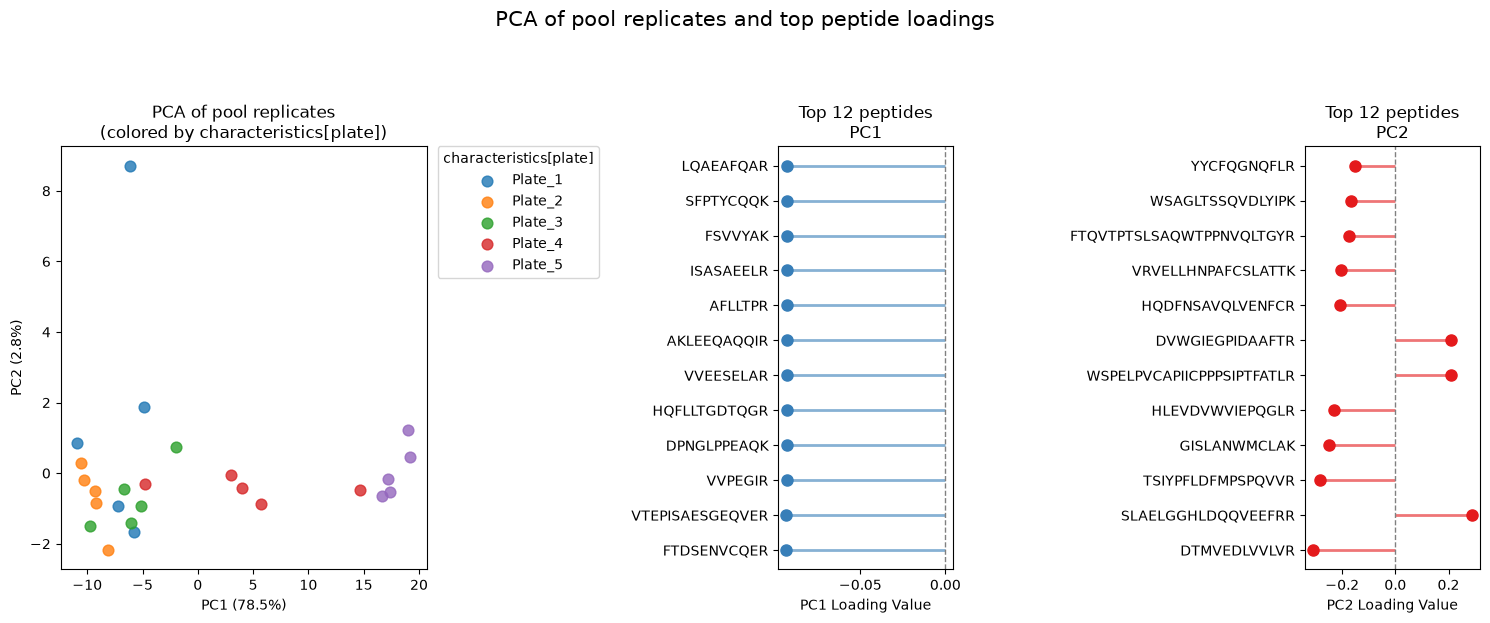

In [24]:
kdm.plot_pool_pca(pool_selected_df)

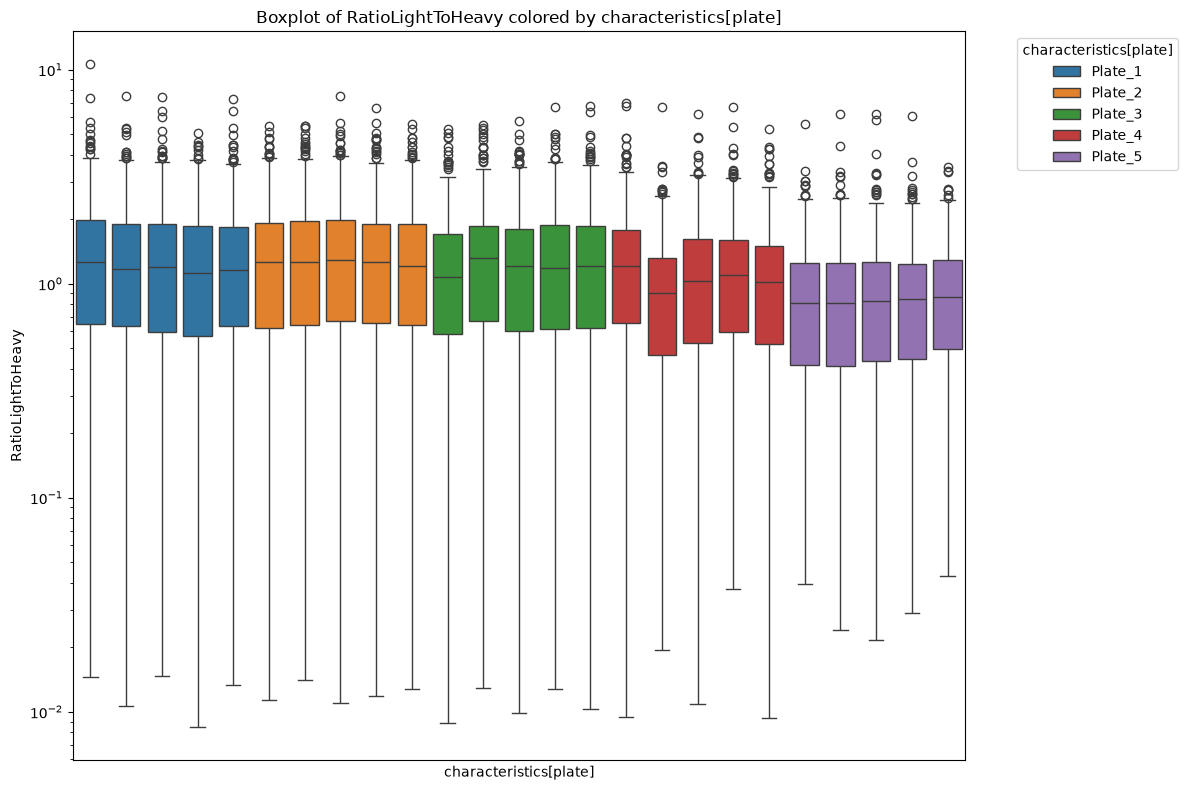

In [25]:
kdm.plot_pool_boxplot(pool_selected_df)

In [26]:
plate_factor_table, conversion_factors, model = kdm.get_plate_conversion_factors(pool_selected_df, col_plate='characteristics[plate]', log_transform=True  )

Conversion factors: {'Plate_1': 0.9610129304884575, 'Plate_2': 0.9110112241565628, 'Plate_3': 0.9706337535703025, 'Plate_4': 1.1451391046405193, 'Plate_5': 1.4429696297914483}


In [27]:
plate_factor_table

,characteristics[plate],plate_median,correction_factor
0,Plate_1,1.040569,0.961013
1,Plate_2,1.097681,0.911011
2,Plate_3,1.030255,0.970634
3,Plate_4,0.873256,1.145139
4,Plate_5,0.693015,1.442970


In [28]:
conversion_factors

{'Plate_1': 0.9610129304884575,
 'Plate_2': 0.9110112241565628,
 'Plate_3': 0.9706337535703025,
 'Plate_4': 1.1451391046405193,
 'Plate_5': 1.4429696297914483}

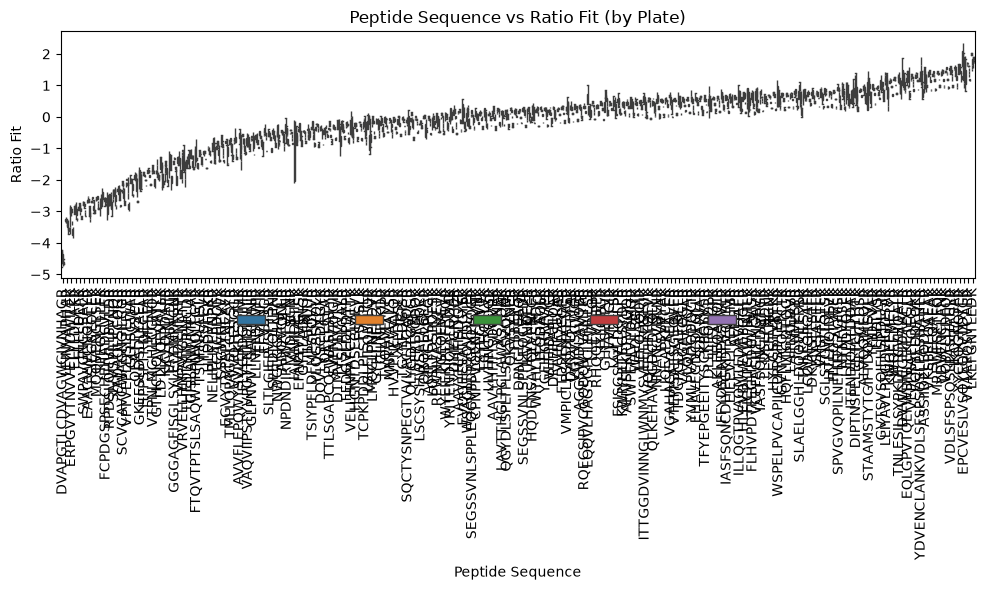

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [29]:
kdm.plot_plate_conversion_factors(pool_selected_df, col_plate='characteristics[plate]', log_transform=True  )

In [30]:
teapot_merge_adj = teapot_merge.copy()

In [31]:
# Adjust ratio by conversion factor 
teapot_merge_adj = kdm.adjust_ratio_by_plate(teapot_merge_adj, conversion_factors)

teapot_merge_adj.head()

,Precursor,Replicate,File Name,Peptide Retention Time,Precursor Charge,Peptide Sequence,Peptide,Normalized Area,RatioLightToHeavy,Protein Name,...,characteristics[ancestry category],characteristics[cell type],characteristics[cell line],characteristics[disease],characteristics[96w_pos],characteristics[96w_plate_coordinate],characteristics[LIMS_ID],characteristics[individual],characteristics[biological replicate],factor value[Sample]
0,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,12.328428,2,ITQDAQLK,ITQDAQLK,1822630.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
1,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_D10,PRM_20251128_MarthaReselection_Plate_1_D10.raw,12.305622,2,ITQDAQLK,ITQDAQLK,1632830.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,76,Plate_1_D10,EMPTY-0001,not available,1,Pool
2,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_F12,PRM_20251128_MarthaReselection_Plate_1_F12.raw,12.320438,2,ITQDAQLK,ITQDAQLK,1533720.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,94,Plate_1_F12,EMPTY-0001,not available,1,Pool
3,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_G12,PRM_20251128_MarthaReselection_Plate_1_G12.raw,12.340083,2,ITQDAQLK,ITQDAQLK,1892230.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,95,Plate_1_G12,EMPTY-0001,not available,1,Pool
4,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_H12,PRM_20251128_MarthaReselection_Plate_1_H12.raw,12.402933,2,ITQDAQLK,ITQDAQLK,1948050.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,96,Plate_1_H12,EMPTY-0001,not available,1,Pool


In [32]:
# From teapot_merge_adj, filter to pool samples
pool_data_adj = teapot_merge_adj[teapot_merge_adj['characteristics[Sample]'] == 'Pool'].copy()

# Reorder by characteristics[Plate]
pool_data_adj = pool_data_adj.sort_values(by='characteristics[plate]')

pool_data_adj.head()

,Precursor,Replicate,File Name,Peptide Retention Time,Precursor Charge,Peptide Sequence,Peptide,Normalized Area,RatioLightToHeavy,Protein Name,...,characteristics[ancestry category],characteristics[cell type],characteristics[cell line],characteristics[disease],characteristics[96w_pos],characteristics[96w_plate_coordinate],characteristics[LIMS_ID],characteristics[individual],characteristics[biological replicate],factor value[Sample]
0,ITQDAQLK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,12.328428,2,ITQDAQLK,ITQDAQLK,1822630.0,NaN,QR0140840_SERPINA6|P08185,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool
6263,SSGWHFVVK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_G12,PRM_20251128_MarthaReselection_Plate_1_G12.raw,18.086487,2,SSGWHFVVK,SSGWHFVVK,1512050.0,NaN,QR4180150_C7|P10643,...,not available,not available,not available,not available,95,Plate_1_G12,EMPTY-0001,not available,1,Pool
6264,SSGWHFVVK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_H12,PRM_20251128_MarthaReselection_Plate_1_H12.raw,18.183222,2,SSGWHFVVK,SSGWHFVVK,1367140.0,NaN,QR4180150_C7|P10643,...,not available,not available,not available,not available,96,Plate_1_H12,EMPTY-0001,not available,1,Pool
10497,DPNGLPPEAQK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_D10,PRM_20251128_MarthaReselection_Plate_1_D10.raw,13.875957,2,DPNGLPPEAQK,DPNGLPPEAQK,12051700.0,NaN,QR7000009_RBP4|P02753,...,not available,not available,not available,not available,76,Plate_1_D10,EMPTY-0001,not available,1,Pool
10496,DPNGLPPEAQK++ (heavy),PRM_20251128_MarthaReselection_Plate_1_B2,PRM_20251128_MarthaReselection_Plate_1_B2.raw,13.856946,2,DPNGLPPEAQK,DPNGLPPEAQK,13502800.0,NaN,QR7000009_RBP4|P02753,...,not available,not available,not available,not available,10,Plate_1_B2,EMPTY-0001,not available,1,Pool


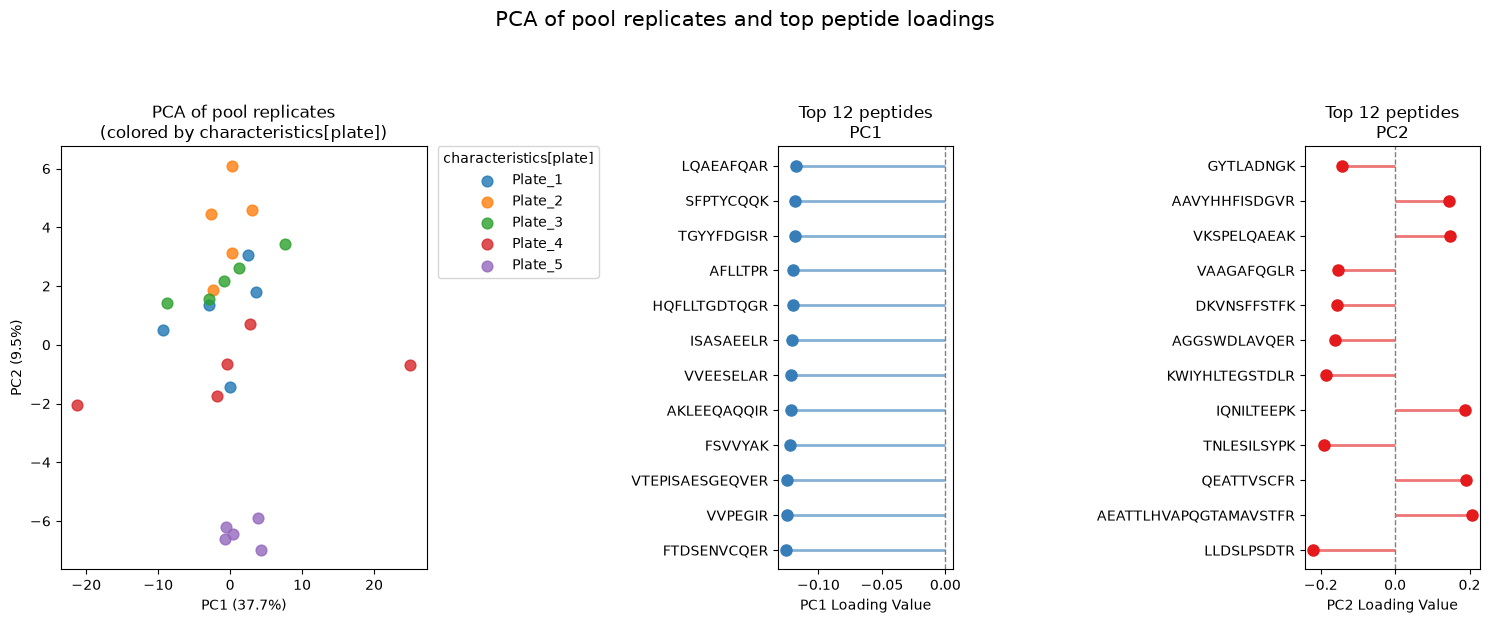

In [33]:
# Show pca of pool data
kdm.plot_pool_pca(pool_data_adj)

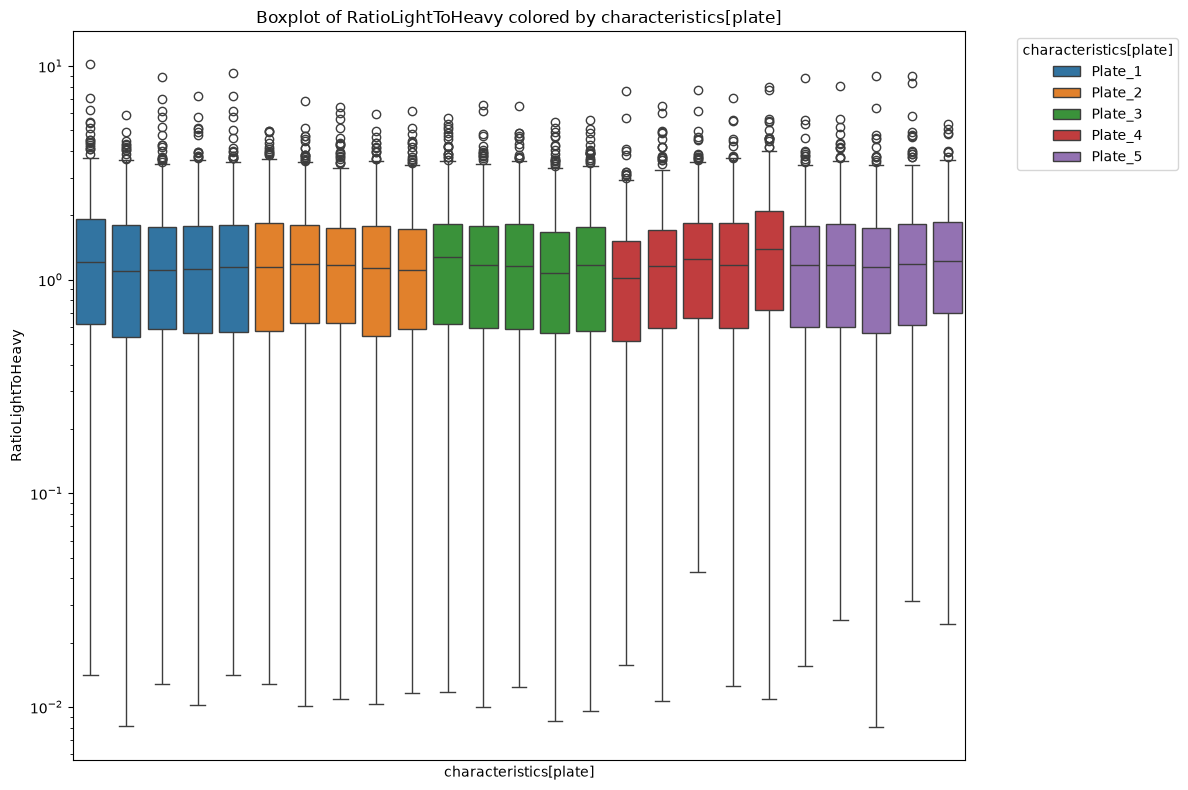

In [34]:
# Show boxplot of pool data
kdm.plot_pool_boxplot(pool_data_adj)

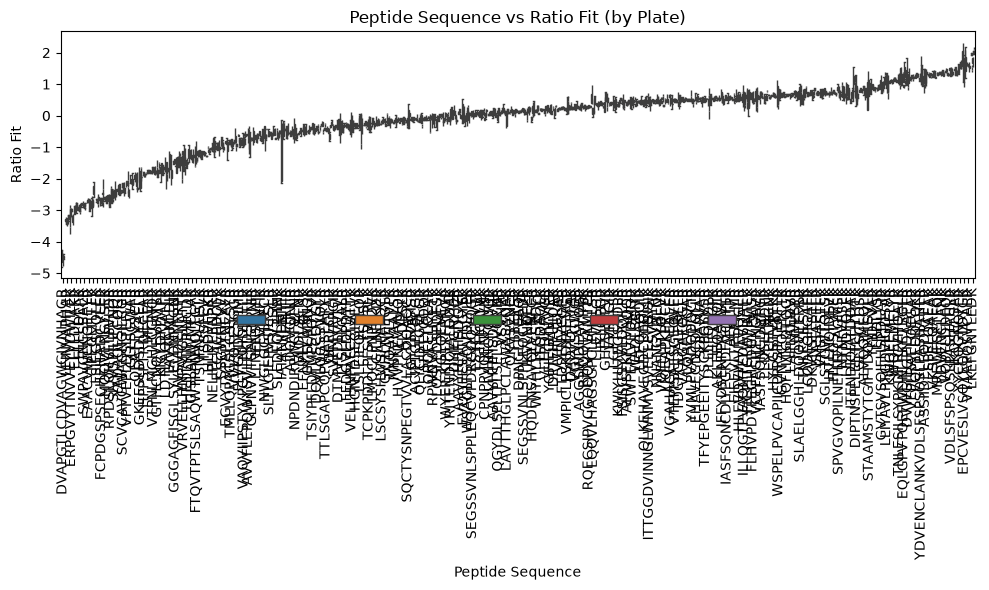

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [35]:
pool_selected_adj = pool_data_adj[pool_data_adj['Peptide Sequence'].isin(selected_peptides)]

kdm.plot_plate_conversion_factors(pool_selected_adj, col_plate='characteristics[plate]', log_transform=True  )

## Method 2: PERMANOVA-driven per-peptide correction (batch_correct.py)

Test every `characteristics[*]` column for batch effects with PERMANOVA, then use `correct_ratio_by_factors` to median-center ratios per peptide for each significant factor (sequentially).

In [36]:
# PERMANOVA test for batch effects across all characteristics columns
permanova_results = kdm.permanova_batch_effects(teapot_pool)

# Suggested factors to correct for (p < 0.05)
sig_factors = permanova_results[permanova_results["p_value"] < 0.05]["variable"].tolist()
print("Suggested factors to correct for batch effect (p < 0.05):", sig_factors)

permanova_results


PERMANOVA batch effect summary  (999 permutations)
Significant factors (p < 0.05):  1
  **  characteristics[plate]
       p = 0.0010  |  F = 11.199  |  R² = 0.691 (large effect)  |  5 groups, 25 samples

Non-significant factors (p >= 0.05):  7
       characteristics[Column]
       p = 0.2330  |  F = 1.357  |  R² = 0.162  |  4 groups, 25 samples
       characteristics[Position]
       p = 0.8400  |  F = 0.724  |  R² = 0.420  |  13 groups, 25 samples
       characteristics[96w_pos]
       p = 0.8460  |  F = 0.724  |  R² = 0.420  |  13 groups, 25 samples
       characteristics[Source Vial]
       p = 0.8470  |  F = 0.724  |  R² = 0.420  |  13 groups, 25 samples
       characteristics[Row]
       p = 0.8510  |  F = 0.635  |  R² = 0.175  |  7 groups, 25 samples
       characteristics[File Name]
       p = 1.0000  |  F = inf  |  R² = nan  |  25 groups, 25 samples
       characteristics[96w_plate_coordinate]
       p = 1.0000  |  F = inf  |  R² = nan  |  25 groups, 25 samples

Skipped (insuf

/nobackup/proj/disk/kall/personal/yuqizh/kardemumma/src/kardemumma/batch_correct.py:238: RuntimeWarning: invalid value encountered in scalar divide
  ss_within = ss_total - (f_obs * ss_total * (k - 1)) / (f_obs * (k - 1) + (n - k))


,variable,F_statistic,p_value,R2,n_groups,n_samples,n_permutations
0,characteristics[plate],11.1994,0.001,0.6913,5,25,999
1,characteristics[Column],1.3565,0.233,0.1623,4,25,999
2,characteristics[Position],0.7237,0.840,0.4198,13,25,999
3,characteristics[96w_pos],0.7237,0.846,0.4198,13,25,999
4,characteristics[Source Vial],0.7237,0.847,0.4198,13,25,999
5,characteristics[Row],0.6350,0.851,0.1747,7,25,999
6,characteristics[File Name],inf,1.000,NaN,25,25,999
7,characteristics[96w_plate_coordinate],inf,1.000,NaN,25,25,999
8,characteristics[Sample],NaN,NaN,NaN,1,25,999
9,characteristics[Inj Vol],NaN,NaN,NaN,1,25,999


In [37]:
# Correct ratios by removing identified batch factors for pool data
teapot_pool_corrected = kdm.correct_ratio_by_factors(
    teapot_pool,
    factors=sig_factors,
    col_ratio="RatioLightToHeavy",
)

# Correct ratio for all data
teapot_corrected = kdm.correct_ratio_by_factors(
    teapot_merge,
    factors=sig_factors,
    col_ratio="RatioLightToHeavy",
)

  Corrected for: characteristics[plate]

Corrected ratios written to 'RatioLightToHeavy_corrected'.
  Corrected for: characteristics[plate]

Corrected ratios written to 'RatioLightToHeavy_corrected'.


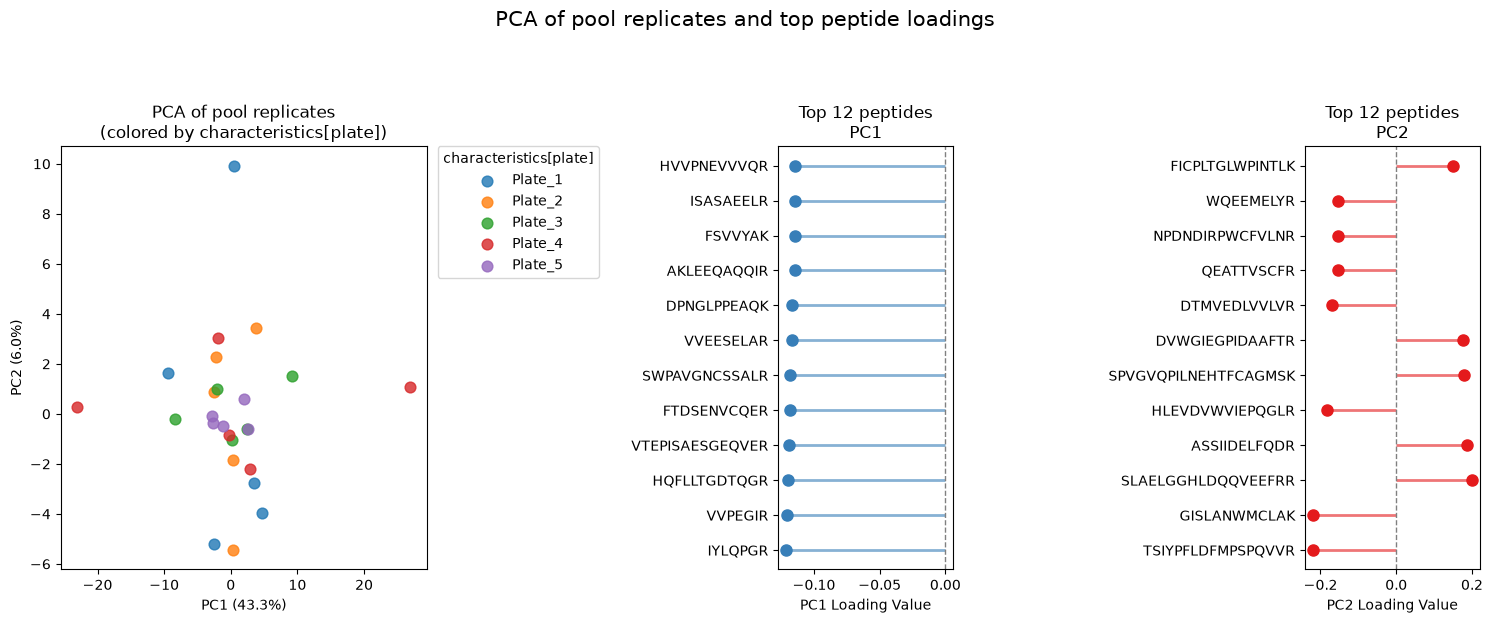

In [38]:
kdm.plot_pool_pca(teapot_corrected, col_ratio="RatioLightToHeavy_corrected")

/nobackup/proj/disk/kall/personal/yuqizh/kardemumma/src/kardemumma/batch_correct.py:238: RuntimeWarning: invalid value encountered in scalar divide
  ss_within = ss_total - (f_obs * ss_total * (k - 1)) / (f_obs * (k - 1) + (n - k))



PERMANOVA batch effect summary  (999 permutations)
No significant batch effects detected (all p >= 0.05).

Non-significant factors (p >= 0.05):  8
       characteristics[Row]
       p = 0.3830  |  F = 1.052  |  R² = 0.260  |  7 groups, 25 samples
       characteristics[Column]
       p = 0.4150  |  F = 1.013  |  R² = 0.126  |  4 groups, 25 samples
       characteristics[Position]
       p = 0.4740  |  F = 1.016  |  R² = 0.504  |  13 groups, 25 samples
       characteristics[Source Vial]
       p = 0.4820  |  F = 1.016  |  R² = 0.504  |  13 groups, 25 samples
       characteristics[96w_pos]
       p = 0.4980  |  F = 1.016  |  R² = 0.504  |  13 groups, 25 samples
       characteristics[File Name]
       p = 1.0000  |  F = inf  |  R² = nan  |  25 groups, 25 samples
       characteristics[plate]
       p = 1.0000  |  F = 0.452  |  R² = 0.083  |  5 groups, 25 samples
       characteristics[96w_plate_coordinate]
       p = 1.0000  |  F = inf  |  R² = nan  |  25 groups, 25 samples

Skipped (

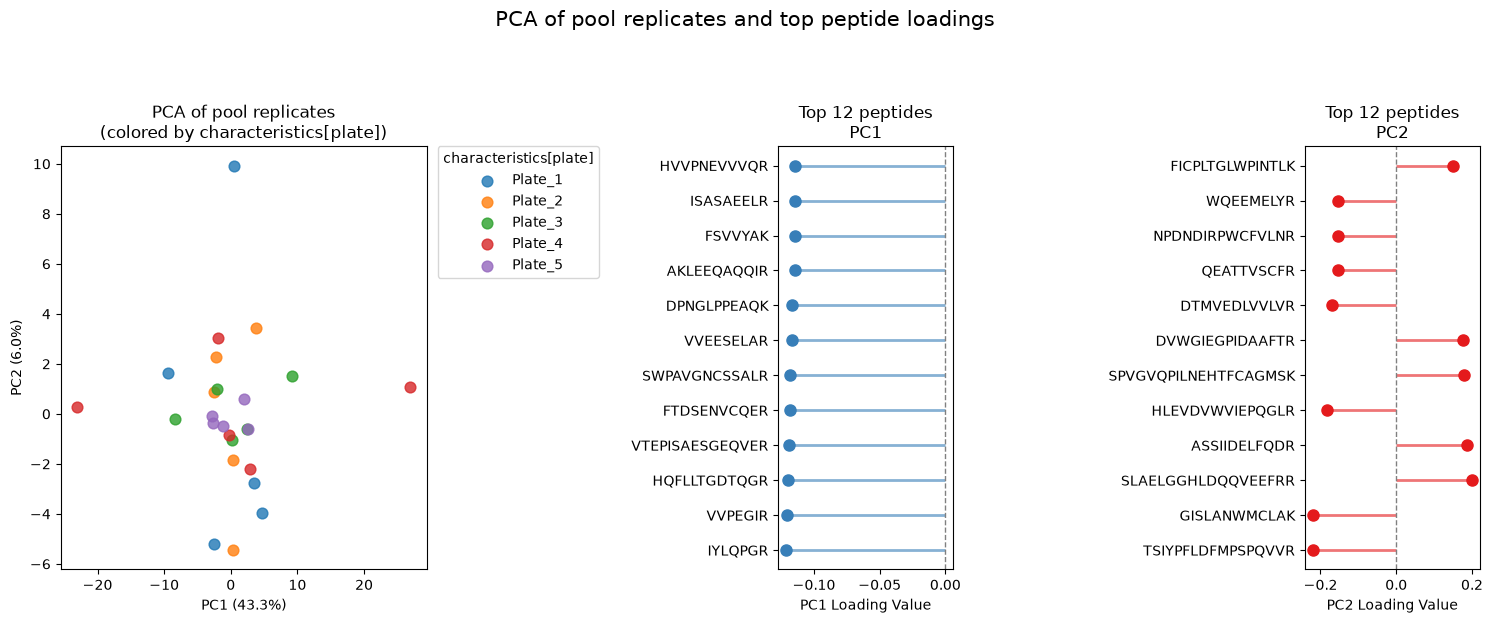

In [39]:
# Verify batch correction — PERMANOVA on corrected ratios
permanova_corrected = kdm.permanova_batch_effects(
    teapot_pool_corrected,
    col_ratio="RatioLightToHeavy_corrected",
)

# Visual check
kdm.plot_pool_pca(teapot_pool_corrected, col_ratio="RatioLightToHeavy_corrected")

## Comparison of the two batch-correction methods

  Corrected for: characteristics[plate]

Corrected ratios written to 'RatioLightToHeavy_corrected'.


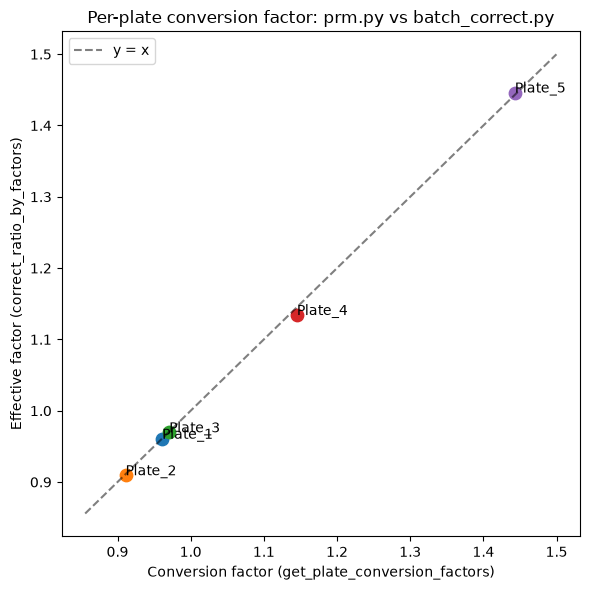

In [40]:
# Compare per-plate conversion factors between the two batch-adjustment approaches:
#   1) get_plate_conversion_factors (prm.py): single global factor per plate
#   2) correct_ratio_by_factors (batch_correct.py): per-peptide correction; aggregated to
#      an effective per-plate factor as median(corrected / original) for a fair comparison.
# Both use the same peptide subset (pool_selected_df) and isolate the plate factor only.

pool_selected_plate_corrected = kdm.correct_ratio_by_factors(
    pool_selected_df,
    factors=['characteristics[plate]'],
    col_ratio="RatioLightToHeavy",
)
pool_selected_plate_corrected['_effective_factor'] = (
    pool_selected_plate_corrected['RatioLightToHeavy_corrected']
    / pool_selected_plate_corrected['RatioLightToHeavy']
)
batch_correct_factors = (
    pool_selected_plate_corrected.groupby('characteristics[plate]')['_effective_factor'].median()
)
batch_correct_factors.index = batch_correct_factors.index.astype(str)

prm_factors = pd.Series(conversion_factors, name='prm_factor')

compare_df = pd.DataFrame({
    'prm_conversion_factor': prm_factors,
    'batch_correct_factor': batch_correct_factors,
}).dropna()

fig, ax = plt.subplots(figsize=(6, 6))
for plate, row in compare_df.iterrows():
    ax.scatter(row['prm_conversion_factor'], row['batch_correct_factor'], s=80)
    ax.annotate(plate, (row['prm_conversion_factor'], row['batch_correct_factor']))
lo, hi = compare_df.values.min(), compare_df.values.max()
pad = (hi - lo) * 0.1 or 0.1
ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', alpha=0.5, label='y = x')
ax.set_xlabel('Conversion factor (get_plate_conversion_factors)')
ax.set_ylabel('Effective factor (correct_ratio_by_factors)')
ax.set_title('Per-plate conversion factor: prm.py vs batch_correct.py')
ax.legend()
plt.tight_layout()
plt.show()

# Calculate absolute quantification

teapot quantified with the known amount of each standard (`heavy_pmol_known`), carried in `Heavy Amount [pmol]`; those amounts are used in place of the qRePS table of the lot. The ratios are those corrected by plate (Method 1).

In [41]:
# Calculate absolute protein concentration
abs_df = kdm.get_absolute_conc(None, teapot_merge_adj, amount_col="Heavy Amount [pmol]")

Number of out of bounds ratios: 0
Ratio cutoff low: 0.001
Ratio cutoff high: 1000
Number of unique qRePS ids: 102
Number of unique Peptide Sequences: 229
Number of unique Protein Names: 102
Number of unique File Names: 25


In [42]:
# Print out the table
abs_df.head()

File Name                                             PRM_20251128_MarthaReselection_Plate_1_B2.raw  \
qRePS     Peptide Sequence Protein Name                                                               
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                       0.541427   
          MNTVIAALSR       QR0140840_SERPINA6|P08185                                       0.478032   
          WSAGLTSSQVDLYIPK QR0140840_SERPINA6|P08185                                       0.540735   
QR0252445 ALDLSLK          QR0252445_ITIH3|Q06033                                          0.207994   
          DYIFGNYIER       QR0252445_ITIH3|Q06033                                          0.282507   

File Name                                             PRM_20251128_MarthaReselection_Plate_1_D10.raw  \
qRePS     Peptide Sequence Protein Name                                                                
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                        0.518312   
          MNTVIAALSR       QR0140840_SERPINA6|P08185                                        0.335117   
          WSAGLTSSQVDLYIPK QR0140840_SERPINA6|P08185                                        0.369453   
QR0252445 ALDLSLK          QR0252445_ITIH3|Q06033                                           0.264027   
          DYIFGNYIER       QR0252445_ITIH3|Q06033                                           0.333069   

File Name                                             PRM_20251128_MarthaReselection_Plate_1_F12.raw  \
qRePS     Peptide Sequence Protein Name                                                                
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                        0.509999   
          MNTVIAALSR       QR0140840_SERPINA6|P08185                                        0.328754   
          WSAGLTSSQVDLYIPK QR0140840_SERPINA6|P08185                                        0.296905   
QR0252445 ALDLSLK          QR0252445_ITIH3|Q06033                                           0.175440   
          DYIFGNYIER       QR0252445_ITIH3|Q06033                                           0.277441   

File Name                                             PRM_20251128_MarthaReselection_Plate_1_G12.raw  \
qRePS     Peptide Sequence Protein Name                                                                
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                        0.483320   
          MNTVIAALSR       QR0140840_SERPINA6|P08185                                        0.326480   
          WSAGLTSSQVDLYIPK QR0140840_SERPINA6|P08185                                        0.346253   
QR0252445 ALDLSLK          QR0252445_ITIH3|Q06033                                           0.209189   
          DYIFGNYIER       QR0252445_ITIH3|Q06033                                           0.241718   

File Name                                             PRM_20251128_MarthaReselection_Plate_1_H12.raw  \
qRePS     Peptide Sequence Protein Name                                                                
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                        0.504403   
          MNTVIAALSR       QR0140840_SERPINA6|P08185                                        0.306346   
          WSAGLTSSQVDLYIPK QR0140840_SERPINA6|P08185                                        0.447305   
QR0252445 ALDLSLK          QR0252445_ITIH3|Q06033                                           0.183270   
          DYIFGNYIER       QR0252445_ITIH3|Q06033                                           0.239316   

File Name                                             PRM_20251128_MarthaReselection_Plate_2_C2.raw  \
qRePS     Peptide Sequence Protein Name                                                               
QR0140840 ITQDAQLK         QR0140840_SERPINA6|P08185                                       0.489464   
          MNTVIAALSR       QR0140840_SERPINA6|P08185 

In [43]:
sdrf_data_file['factor value[Sample]'].unique()

<StringArray>
['Pool']
Length: 1, dtype: str

# Downstream analysis

The 25 runs are all pools of one plasma, so there are no groups to compare. Each peptide's median amount per plate, after the plate correction:

In [44]:
abs_long = (
    abs_df.reset_index()
    .melt(id_vars=["qRePS", "Peptide Sequence", "Protein Name"], var_name="comment[data file]",
          value_name="Protein conc [pmol]")
    .dropna(subset=["Protein conc [pmol]"])
    .merge(sdrf_data_file[["comment[data file]", "characteristics[plate]"]], on="comment[data file]")
)
abs_long.groupby(["Protein Name", "Peptide Sequence", "characteristics[plate]"])["Protein conc [pmol]"].median().unstack().head(10)

characteristics[plate]                         Plate_1   Plate_2   Plate_3  \
Protein Name              Peptide Sequence                                   
QR0140840_SERPINA6|P08185 ITQDAQLK            0.509999  0.501472  0.495919   
                          MNTVIAALSR          0.328754  0.345071  0.353594   
                          WSAGLTSSQVDLYIPK    0.369453  0.442204  0.454165   
QR0252445_ITIH3|Q06033    ALDLSLK             0.207994  0.215149  0.207552   
                          DYIFGNYIER          0.277441  0.260733  0.229490   
QR0260124_APOA4|P06727    ALVQQMEQLR          2.729854  2.411155  2.464734   
                          DKVNSFFSTFK         2.256769  2.219215  2.086852   
                          ISASAEELR           2.254922  2.326477  2.297940   
                          LAPLAEDVR           2.145096  2.183641  2.178699   
                          SLAELGGHLDQQVEEFRR  2.067165  2.564846  2.233835   

characteristics[plate]                         Plate_4   Plate_5  
Protein Name              Peptide Sequence                        
QR0140840_SERPINA6|P08185 ITQDAQLK            0.501369  0.494493  
                          MNTVIAALSR          0.360980  0.361729  
                          WSAGLTSSQVDLYIPK    0.437955  0.428075  
QR0252445_ITIH3|Q06033    ALDLSLK             0.204185  0.192454  
                          DYIFGNYIER          0.218525  0.199848  
QR0260124_APOA4|P06727    ALVQQMEQLR          2.427961  2.502504  
                          DKVNSFFSTFK         2.279449  2.534802  
                          ISASAEELR           2.340021  2.232000  
                          LAPLAEDVR           2.182484  2.247227  
                          SLAELGGHLDQQVEEFRR  2.219743  2.088853